# Exhaustive validation: comparing the 9 architectures

Compares the 9 engine architectures (R, RV, IS, OPT, OPT2, ML, ML2, RL, RL2) competing
against each other for real -- not in isolated 1v1 duels -- under three market conditions:

| Condition | Carriers | Shippers | What it tests |
|---|---|---|---|
| `balanced` | 9 (all 9) | 9 (all 9) | Baseline, no scarcity pressure |
| `carrier_scarce` | 7 (2 excluded, rotating) | 9 (all 9) | Shippers competing for few carriers |
| `shipper_scarce` | 9 (all 9) | 7 (2 excluded, rotating) | Carriers competing for few shippers |

**Design**: each architecture appears at most once per side per negotiation (no
self-competition between copies of the same engine -- with several copies of one engine,
part of the result would be "it beats itself", not the others). In the scarce conditions,
which pair of architectures is excluded in each run is ROTATED systematically through all
C(9,2)=36 possible combinations, so that no architecture is systematically favoured or
penalised by the experimental design itself.

**Cache**: the first time this notebook runs, it simulates everything and saves the raw
results to `data/validation/raw_results.csv`. On later runs, if that file exists, it is
loaded directly -- the simulation is not re-run. To force a re-run (for example after
changing an engine), set `FORCE_RERUN = True` in the parameters cell.

The 9:7 ratio was chosen because it approximates the original ratio of the WHAD design
document (4 shippers : 3 carriers ~= 1.33, and 9:7 ~= 1.29) rather than being arbitrary.


In [1]:
import itertools
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT.parent))  # repo root: the wehaveadeal package
import os
os.chdir(PROJECT_ROOT)  # paper/ -- data/ and figures/ below are relative to it

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests

from wehaveadeal.simulate import CARRIER_KINDS, SHIPPER_KINDS, build_carrier, build_shipper, run_round

assert CARRIER_KINDS == SHIPPER_KINDS
ALL_KINDS = list(CARRIER_KINDS)
ARCH_LABELS = {"r": "R", "rv": "RV", "is": "IS", "opt": "OPT", "opt2": "OPT2",
               "ml": "ML", "ml2": "ML2", "rl": "RL", "rl2": "RL2"}

sns.set_theme(style="whitegrid")

print(f"{len(ALL_KINDS)} architectures: {ALL_KINDS}")


9 architectures: ['r', 'rv', 'is', 'opt', 'opt2', 'ml', 'ml2', 'rl', 'rl2']


## Experiment parameters

Adjust these values before forcing a re-run. With `N_PER_PAIR_SCARCE` negotiations for
each of the 36 excluded pairs, each architecture appears in 28 of the 36 pairs (it is
excluded only in the 8 pairs that contain it), so its real effective N is lower than the
nominal one -- we compute it and verify it directly from the data below rather than
assuming it.


In [2]:
N_BALANCED = 400          # negotiations in the balanced condition (a single run)
N_PER_PAIR_SCARCE = 12    # negotiations for each of the 36 excluded pairs -> 432 negotiations/condition
FORCE_RERUN = False        # True to ignore the cache and re-simulate everything

DATA_DIR = PROJECT_ROOT / "data" / "validation"
DATA_DIR.mkdir(parents=True, exist_ok=True)
RAW_CACHE_PATH = DATA_DIR / "raw_results.csv"

effective_n_scarce = N_PER_PAIR_SCARCE * 36 * (len(ALL_KINDS) - 2) / len(ALL_KINDS)
print(f"balanced: {N_BALANCED} negotiations, N per architecture = {N_BALANCED}")
print(f"scarce:   {N_PER_PAIR_SCARCE} x 36 pairs = {N_PER_PAIR_SCARCE * 36} negotiations, "
      f"effective N per architecture ~= {effective_n_scarce:.0f}")


balanced: 400 negotiations, N per architecture = 400
scarce:   12 x 36 pairs = 432 negotiations, effective N per architecture ~= 336


## Simulation engine

Reuses `wehaveadeal.simulate.run_round` unmodified -- we build the roster ourselves
(one instance per architecture, never more than one copy of the same engine per side) and
extract tidy rows from each `NegotiationResult` the engine has already computed
(the same `margin`/`profit` used everywhere else in the project, 0 if unmatched).


In [3]:
def build_roster(kinds, role: str):
    builder = build_carrier if role == "carrier" else build_shipper
    engines, id_to_kind = {}, {}
    for kind in kinds:
        agent_id = f"{role}-{kind}-1"
        engines[agent_id] = builder(kind, agent_id)
        id_to_kind[agent_id] = kind
    return engines, id_to_kind


def extract_rows(round_result, config: str, excluded_label: str, carrier_id_to_kind, shipper_id_to_kind):
    rows = []
    for neg in round_result.negotiations:
        day_id = f"{config}|{excluded_label}|{round_result.seed}|{neg.negotiation_index}"
        for co in neg.carrier_outcomes:
            rows.append({
                "config": config, "excluded": excluded_label, "day_id": day_id,
                "role": "carrier", "kind": carrier_id_to_kind[co.carrier_id],
                "matched": co.matched, "outcome": co.margin,
            })
        for so in neg.shipper_outcomes:
            rows.append({
                "config": config, "excluded": excluded_label, "day_id": day_id,
                "role": "shipper", "kind": shipper_id_to_kind[so.shipper_id],
                "matched": so.matched, "outcome": so.profit,
            })
    return rows


def run_balanced(seed_base: int, n_negotiations: int):
    carriers, c_map = build_roster(ALL_KINDS, "carrier")
    shippers, s_map = build_roster(ALL_KINDS, "shipper")
    result = run_round(round_index=0, seed=seed_base, shipper_engines=shippers,
                        carrier_engines=carriers, n_negotiations=n_negotiations)
    return extract_rows(result, "balanced", "none", c_map, s_map)


def run_scarce(seed_base: int, scarce_role: str, n_per_pair: int):
    """`scarce_role` ('carrier' or 'shipper') gets 7 of 9 kinds per sub-round; the
    other role keeps all 9. Which 2 kinds are missing cycles through all C(9,2)=36
    combinations, so every architecture is excluded from an equal number of sub-rounds."""
    rows = []
    pairs = list(itertools.combinations(ALL_KINDS, 2))
    for i, pair in enumerate(pairs):
        kept_scarce = [k for k in ALL_KINDS if k not in pair]
        if scarce_role == "carrier":
            carriers, c_map = build_roster(kept_scarce, "carrier")
            shippers, s_map = build_roster(ALL_KINDS, "shipper")
        else:
            shippers, s_map = build_roster(kept_scarce, "shipper")
            carriers, c_map = build_roster(ALL_KINDS, "carrier")
        result = run_round(round_index=i, seed=seed_base + i, shipper_engines=shippers,
                            carrier_engines=carriers, n_negotiations=n_per_pair)
        config_name = f"{scarce_role}_scarce"
        rows += extract_rows(result, config_name, "+".join(pair), c_map, s_map)
    return rows


## Run (or load from cache)

In [4]:
if RAW_CACHE_PATH.exists() and not FORCE_RERUN:
    raw = pd.read_csv(RAW_CACHE_PATH)
    print(f"Loaded from cache: {RAW_CACHE_PATH.relative_to(PROJECT_ROOT)} ({len(raw)} rows)")
else:
    print("Running the full simulation (this can take a few minutes)...")
    all_rows = []
    all_rows += run_balanced(seed_base=10_000_000, n_negotiations=N_BALANCED)
    print(f"  balanced done: {len(all_rows)} rows so far")
    all_rows += run_scarce(seed_base=20_000_000, scarce_role="carrier", n_per_pair=N_PER_PAIR_SCARCE)
    print(f"  carrier_scarce done: {len(all_rows)} rows so far")
    all_rows += run_scarce(seed_base=30_000_000, scarce_role="shipper", n_per_pair=N_PER_PAIR_SCARCE)
    print(f"  shipper_scarce done: {len(all_rows)} rows so far")

    raw = pd.DataFrame(all_rows)
    raw.to_csv(RAW_CACHE_PATH, index=False)
    print(f"Saved to {RAW_CACHE_PATH.relative_to(PROJECT_ROOT)}")

raw["arch"] = raw["kind"].map(ARCH_LABELS)
CONFIGS = ["balanced", "carrier_scarce", "shipper_scarce"]
raw.head()


Loaded from cache: data\validation\raw_results.csv (21024 rows)


,config,excluded,day_id,role,kind,matched,outcome,arch
0,balanced,none,balanced|none|10000000|0,carrier,r,True,-48.881176,R
1,balanced,none,balanced|none|10000000|0,carrier,rv,True,-213.397182,RV
2,balanced,none,balanced|none|10000000|0,carrier,is,True,68.095125,IS
3,balanced,none,balanced|none|10000000|0,carrier,opt,True,535.614575,OPT
4,balanced,none,balanced|none|10000000|0,carrier,opt2,True,65.576782,OPT2


## Verifying the real effective N

We do not assume the expected N from a calculation -- we count it directly from the data,
because that is the only honest way to report it afterwards.


In [5]:
n_table = raw.groupby(["config", "role", "arch"]).size().unstack("arch")
n_table


arch                     IS   ML  ML2  OPT  OPT2    R   RL  RL2   RV
config         role                                                 
balanced       carrier  400  400  400  400   400  400  400  400  400
               shipper  400  400  400  400   400  400  400  400  400
carrier_scarce carrier  336  336  336  336   336  336  336  336  336
               shipper  432  432  432  432   432  432  432  432  432
shipper_scarce carrier  432  432  432  432   432  432  432  432  432
               shipper  336  336  336  336   336  336  336  336  336

## Descriptive statistics with (bootstrap) confidence intervals

`outcome` is the margin (carrier) or profit (shipper) of that architecture on that day, 0 if
it was not matched (the same convention as the rest of the project). We use a bootstrap
instead of a normal interval because we already know, from earlier validations in this
project, that these distributions are far from symmetric.


In [6]:
from wehaveadeal.stats import bootstrap_ci  # shared with analyze_llm_validation.ipynb

summary_rows = []
for (config, role, arch), g in raw.groupby(["config", "role", "arch"]):
    mean, lo, hi = bootstrap_ci(g["outcome"].to_numpy())
    summary_rows.append({
        "config": config, "role": role, "arch": arch, "n": len(g),
        "match_rate": g["matched"].mean(), "mean_outcome": mean,
        "ci_lo": lo, "ci_hi": hi,
    })
summary = pd.DataFrame(summary_rows).sort_values(["role", "config", "mean_outcome"], ascending=[True, True, False])
summary.to_csv(DATA_DIR / "summary_stats.csv", index=False)
summary


,config,role,arch,n,match_rate,mean_outcome,ci_lo,ci_hi
2,balanced,carrier,ML2,400,0.787500,98.474611,82.160813,115.582972
6,balanced,carrier,RL,400,0.620000,90.368257,74.598940,107.505278
4,balanced,carrier,OPT2,400,0.802500,83.542566,67.740766,101.693412
3,balanced,carrier,OPT,400,0.792500,79.781109,66.464396,94.332536
0,balanced,carrier,IS,400,0.692500,71.431015,57.624214,86.488897
1,balanced,carrier,ML,400,0.885000,46.404401,33.412434,61.873623
7,balanced,carrier,RL2,400,0.917500,28.686439,20.646579,38.232907
8,balanced,carrier,RV,400,0.922500,-21.798709,-38.455363,-2.572769
5,balanced,carrier,R,400,0.930000,-45.765743,-59.005379,-30.998762
24,carrier_scarce,carrier,RL,336,0.842262,141.954032,123.265315,161.960397


## Visualisation: ranking by condition, with confidence intervals

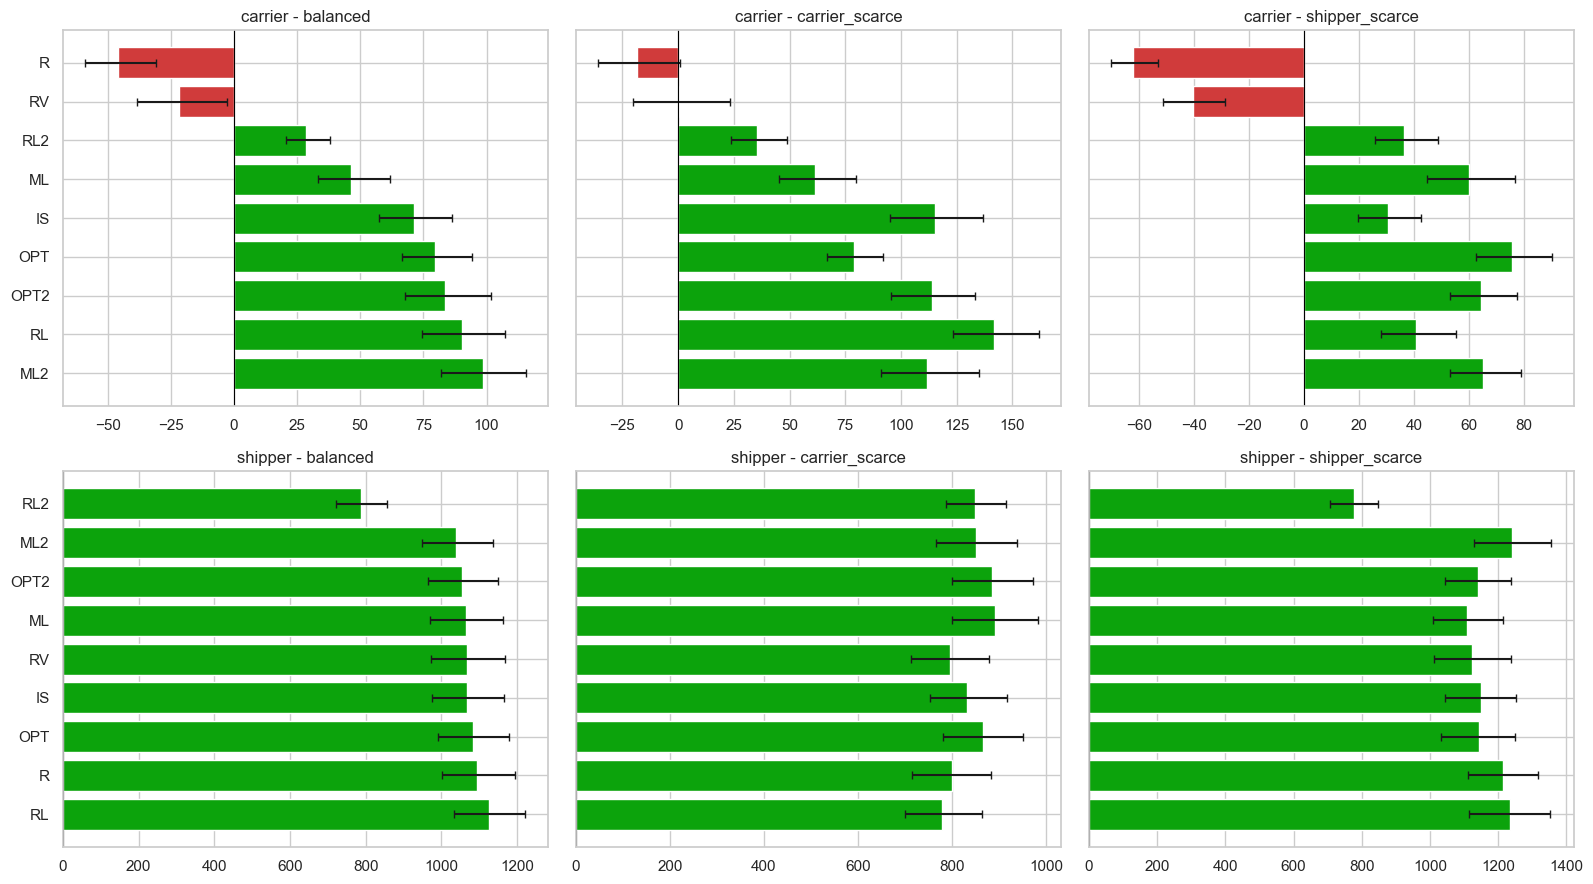

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey="row")
for row_i, role in enumerate(["carrier", "shipper"]):
    for col_i, config in enumerate(CONFIGS):
        ax = axes[row_i, col_i]
        sub = summary[(summary.role == role) & (summary.config == config)].sort_values("mean_outcome", ascending=False)
        colors = ["#0ca30c" if v > 0 else "#d03b3b" for v in sub["mean_outcome"]]
        ax.barh(sub["arch"], sub["mean_outcome"], color=colors,
                xerr=[sub["mean_outcome"] - sub["ci_lo"], sub["ci_hi"] - sub["mean_outcome"]], capsize=3)
        ax.set_title(f"{role} - {config}")
        ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.savefig(DATA_DIR / "ranking_by_config.png", dpi=150)
plt.show()


## Shape of the distribution: violin plot (closed-deal days only)

The bar chart above only shows the mean -- two architectures can tie on the mean while one
is far more consistent (low variance) and the other lives off a few very good days that
offset many mediocre ones. The violin plot shows the full shape of the distribution, not
just its centre.

Important: the violins below use ONLY the days on which a deal closed
(`matched == True`), not the raw `outcome`. `outcome` is 0 when there was no match (the
engine's convention), and mixing those zeros into the same distribution as the real
margins/profits would conflate two different questions ("some of the time it earns
nothing" vs "when it does earn, does it earn well or badly") in a single shape; a point
mass at one exact value is also something a kernel density estimate (KDE) handles poorly.
The match rate is reported separately, in the `summary` table above.


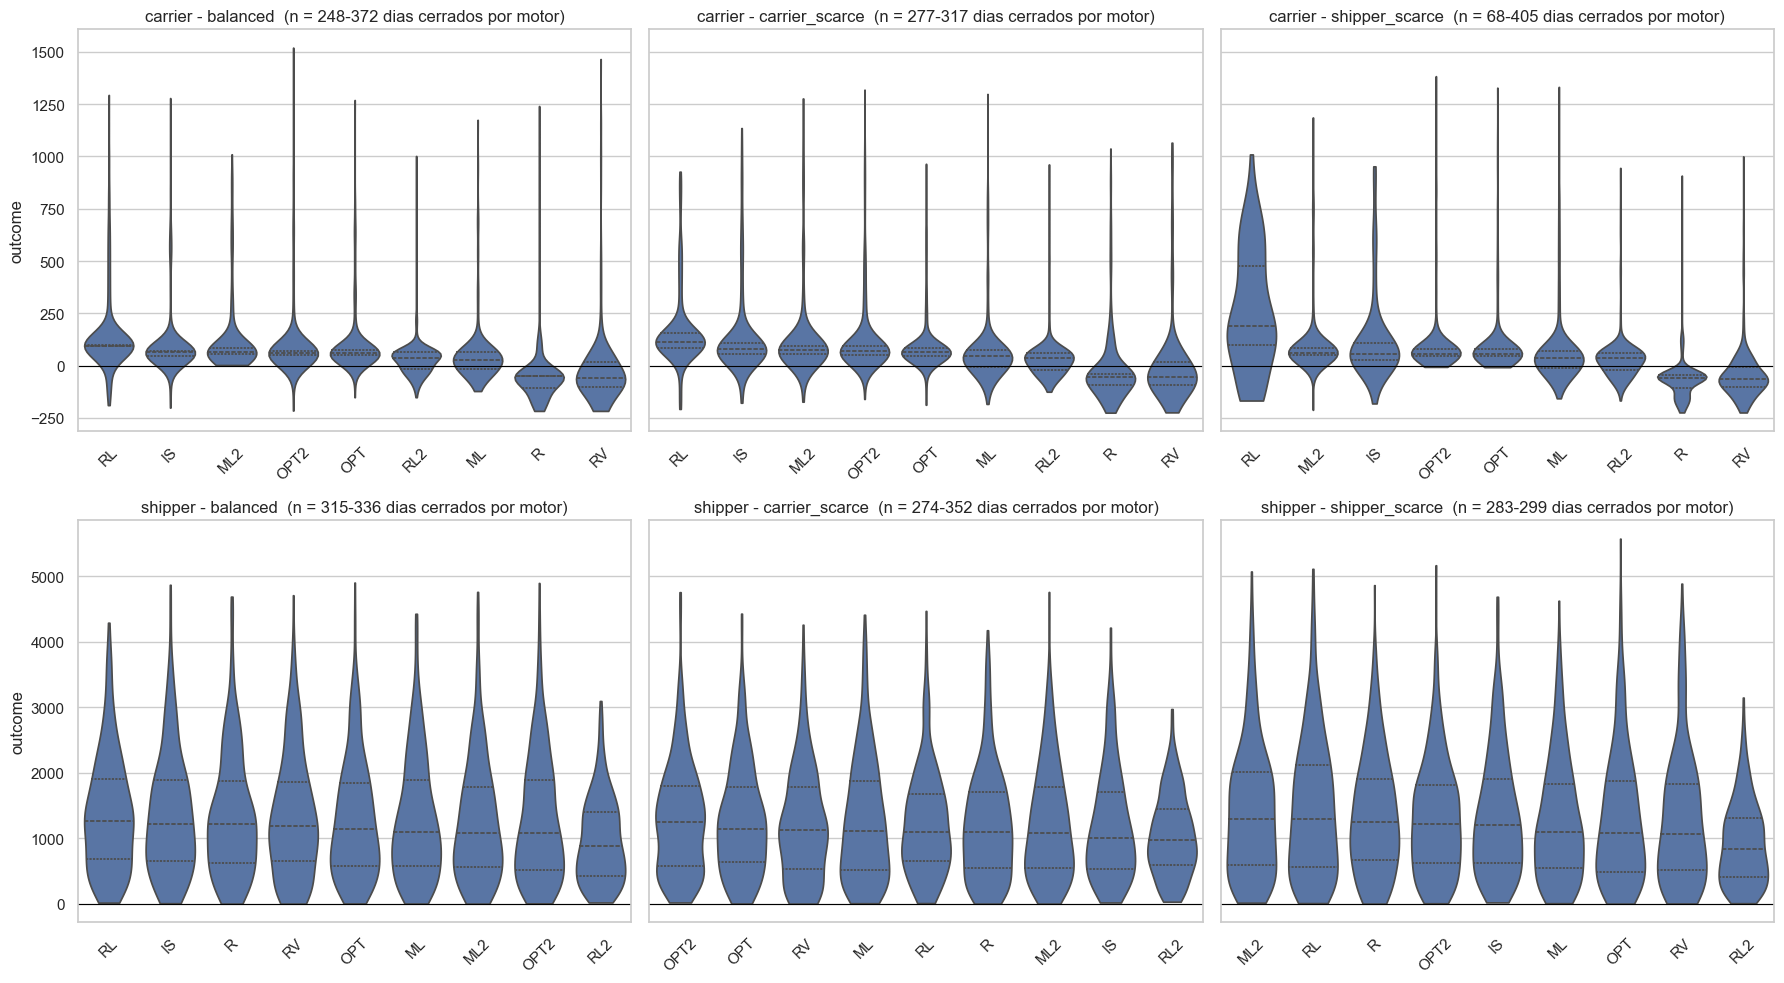

In [8]:
matched_only = raw[raw["matched"]]

fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharey="row")
for row_i, role in enumerate(["carrier", "shipper"]):
    for col_i, config in enumerate(CONFIGS):
        ax = axes[row_i, col_i]
        sub = matched_only[(matched_only.role == role) & (matched_only.config == config)]
        order = sub.groupby("arch")["outcome"].median().sort_values(ascending=False).index
        sns.violinplot(data=sub, x="arch", y="outcome", order=order, ax=ax, cut=0, inner="quartile", density_norm="width")
        n_by_arch = sub.groupby("arch").size()
        ax.set_title(f"{role} - {config}  (n = {n_by_arch.min()}-{n_by_arch.max()} closed-deal days per engine)")
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(DATA_DIR / "violin_matched_outcomes.png", dpi=150)
plt.show()


## Paired (same-day) comparisons with Holm-Bonferroni correction

For each condition and role, we compare every pair of architectures using ONLY the days
on which both were present (in `balanced` that is every day; in the condition that is
scarce on that side, it is the subset of days on which neither of the two was excluded).
We use the Wilcoxon test (non-parametric, appropriate for skewed distributions) on the
day-by-day difference, and correct the p-values of each (condition, role) separately with
Holm-Bonferroni -- 36 comparisons per family, not all 216 together, because each
(condition, role) answers a different question ("who is better under this market
condition"), not the same question repeated.


In [9]:
def paired_diff(df, config, role, kind_a, kind_b):
    sub = df[(df.config == config) & (df.role == role) & (df.kind.isin([kind_a, kind_b]))]
    wide = sub.pivot_table(index="day_id", columns="kind", values="outcome")
    if kind_a not in wide.columns or kind_b not in wide.columns:
        return None
    wide = wide.dropna(subset=[kind_a, kind_b])
    if len(wide) < 10:
        return None
    return (wide[kind_a] - wide[kind_b]).to_numpy()


pairwise_rows = []
for config in CONFIGS:
    for role in ["carrier", "shipper"]:
        kinds_here = sorted(raw[(raw.config == config) & (raw.role == role)]["kind"].unique())
        for kind_a, kind_b in itertools.combinations(kinds_here, 2):
            diff = paired_diff(raw, config, role, kind_a, kind_b)
            if diff is None:
                continue
            mean_diff, ci_lo, ci_hi = bootstrap_ci(diff)
            try:
                _, p = stats.wilcoxon(diff)
            except ValueError:
                p = 1.0
            pairwise_rows.append({
                "config": config, "role": role, "arch_a": ARCH_LABELS[kind_a], "arch_b": ARCH_LABELS[kind_b],
                "n_days": len(diff), "mean_diff": mean_diff, "ci_lo": ci_lo, "ci_hi": ci_hi, "p_raw": p,
            })

pairwise = pd.DataFrame(pairwise_rows)
pairwise["p_holm"] = np.nan
pairwise["significant"] = False
for (config, role), idx in pairwise.groupby(["config", "role"]).groups.items():
    reject, p_corrected, _, _ = multipletests(pairwise.loc[idx, "p_raw"], alpha=0.05, method="holm")
    pairwise.loc[idx, "p_holm"] = p_corrected
    pairwise.loc[idx, "significant"] = reject

pairwise.to_csv(DATA_DIR / "pairwise_tests.csv", index=False)
print(f"{pairwise['significant'].sum()} of {len(pairwise)} comparisons are significant after Holm-Bonferroni (alpha=0.05)")
pairwise.sort_values("p_holm").head(20)


101 of 216 comparisons are significant after Holm-Bonferroni (alpha=0.05)


,config,role,arch_a,arch_b,n_days,mean_diff,ci_lo,ci_hi,p_raw,p_holm,significant
170,shipper_scarce,carrier,OPT2,R,432,126.547569,111.573475,142.433979,2.039496e-59,7.342187e-58,True
166,shipper_scarce,carrier,OPT,R,432,137.517253,121.023248,154.761430,1.270828e-58,4.447896e-57,True
161,shipper_scarce,carrier,ML2,R,432,127.251764,111.313797,143.982156,9.276745e-56,3.154093e-54,True
155,shipper_scarce,carrier,ML,R,432,122.051554,104.498373,140.323504,2.366225e-50,7.808542e-49,True
148,shipper_scarce,carrier,IS,R,432,92.679353,78.358543,107.772870,6.360280e-49,2.035290e-47,True
17,balanced,carrier,ML2,R,400,144.240354,121.487403,166.334403,2.729425e-48,9.825931e-47,True
169,shipper_scarce,carrier,OPT,RV,432,115.754509,97.981199,134.700215,4.508946e-48,1.397773e-46,True
175,shipper_scarce,carrier,R,RL2,432,-98.488099,-113.530106,-84.139397,4.808027e-48,1.442408e-46,True
173,shipper_scarce,carrier,OPT2,RV,432,104.784824,89.015618,121.895955,1.843196e-47,5.345267e-46,True
22,balanced,carrier,OPT,R,400,125.546851,104.483921,144.886105,4.120679e-47,1.442238e-45,True


## "Who beats whom" matrix (only differences significant after correction)

In [ ]:
def plot_win_matrix(role: str, config: str):
    kinds_here = sorted(raw[(raw.config == config) & (raw.role == role)]["kind"].unique())
    archs = [ARCH_LABELS[k] for k in kinds_here]
    mat = pd.DataFrame(0, index=archs, columns=archs, dtype=float)
    sub = pairwise[(pairwise.config == config) & (pairwise.role == role)]
    for _, row in sub.iterrows():
        if not row["significant"]:
            continue
        if row["mean_diff"] > 0:
            mat.loc[row["arch_a"], row["arch_b"]] = 1
        else:
            mat.loc[row["arch_b"], row["arch_a"]] = 1
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(mat, annot=False, cmap="Greens", cbar=False, linewidths=0.5, linecolor="white", ax=ax)
    ax.set_title(f"{role} - {config}\n(row beats column, after Holm-Bonferroni)")
    plt.tight_layout()
    plt.savefig(DATA_DIR / f"win_matrix_{role}_{config}.png", dpi=150)
    plt.show()

for role in ["carrier", "shipper"]:
    for config in CONFIGS:
        plot_win_matrix(role, config)

## Is the ranking stable across scarcity conditions?

If an architecture wins only when the market is balanced but not under scarcity (or the
other way round), that is a real finding worth reporting explicitly -- not something to
hide, in the same spirit of honesty as the rest of this project (we documented RL1's
competitive collapse and RL2's train/deployment gap exactly this way).


In [11]:
rank_table = summary.pivot_table(index=["role", "arch"], columns="config", values="mean_outcome")[CONFIGS]
rank_table["rank_balanced"] = rank_table.groupby(level="role")["balanced"].rank(ascending=False)
rank_table.sort_values(["role", "rank_balanced"])


config           balanced  carrier_scarce  shipper_scarce  rank_balanced
role    arch                                                            
carrier ML2     98.474611      111.935687       65.122473            1.0
        RL      90.368257      141.954032       40.774446            2.0
        OPT2    83.542566      113.794066       64.418278            3.0
        OPT     79.781109       78.736475       75.387963            4.0
        IS      71.431015      115.240008       30.550062            5.0
        ML      46.404401       61.425081       59.922263            6.0
        RL2     28.686439       35.492282       36.358809            7.0
        RV     -21.798709        0.190979      -40.366546            8.0
        R      -45.765743      -18.475707      -62.129290            9.0
shipper RL    1124.800190      779.248184     1233.711284            1.0
        R     1094.420495      800.529856     1212.889017            2.0
        OPT   1082.513431      867.084251     1143.501547            3.0
        IS    1068.855598      833.095294     1149.724816            4.0
        RV    1066.936691      795.445966     1122.908195            5.0
        ML    1063.904757      891.569224     1109.800567            6.0
        OPT2  1055.738022      885.020090     1139.614438            7.0
        ML2   1038.848119      851.968581     1240.758440            8.0
        RL2    788.245130      849.846541      776.789626            9.0